In [1]:
# conda env 'pymap3d'

import pymap3d as pm
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.interpolate import griddata

In [2]:
## INPUT
# RT Grid
rte_grid_file = '../intermediate_data/RTG_1400.nc'
# CTH
cth_file = '../intermediate_data/MISR_CTH_CAMP2Ex_RF17_default.nc'
# Carved Volume
carved_vol_file = '../intermediate_data/CARVED_VOL_th00.nc'
# LCL
lcl = 0.4

isopen = True

## OUTPUT
out_file = '../intermediate_data/CVM_noSC_open.nc'
if os.path.exists(out_file):
    raise Exception('File already exists')

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
cloud_data = xr.load_dataset(cth_file)
carved_volume = xr.load_dataset(carved_vol_file)

In [4]:
def process_cth(cloud_data, rte_grid, plot=True):
    wgs84 = pm.Ellipsoid(model='wgs84')
    e, n, u = pm.geodetic2enu(
        cloud_data.lat1100.data,
        cloud_data.lon1100.data,
        cloud_data.cth.data,
        cloud_data.center_lat.data,
        cloud_data.center_lon.data,
        0.0,
        ell=wgs84,
        deg=True
    )
    cloud_data['E'] = (['y1100', 'x1100'], e/1000)
    cloud_data['N'] = (['y1100', 'x1100'], n/1000)
    cloud_data['z_cloud'] = (['y1100', 'x1100'], u/1000)

    # Horizontal shift to place origin at the corner of the rte grid (maintain centering)
    cloud_data['E'] = cloud_data.E + np.max(rte_grid.x.data)/2
    cloud_data['E'] = cloud_data.E.assign_attrs(units='km')
    cloud_data['N'] = cloud_data.N + np.max(rte_grid.y.data)/2
    cloud_data['N'] = cloud_data.N.assign_attrs(units='km')

    # Create the new grid
    grid_x, grid_y = np.meshgrid(rte_grid.x.data, rte_grid.y.data, indexing='ij')

    # Flatten the original grid and data
    points = np.array([cloud_data.E.data.flatten(), cloud_data.N.data.flatten()]).T
    values = cloud_data.z_cloud.data.flatten()

    # Mask out NaN values
    mask = ~np.isnan(values)
    points = points[mask]
    values = values[mask]

    # Interpolate the data onto the new grid
    cth_interp = griddata(points, values, (grid_x, grid_y), method='linear')

    cth_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, cth_interp, side='right')]

    if(plot):
        levels = np.arange(0, 1.4, 0.1)
        f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
        c0 = ax[0].contourf(cloud_data.E.data, cloud_data.N.data, cloud_data.z_cloud.data, levels=levels)
        plt.colorbar(c0, ax=ax[0], label='Cloud Top Height (km)')
        ax[0].set_title('MISR CTH')
        c1 = ax[1].contourf(grid_x, grid_y, cth_interp, levels=levels)
        plt.colorbar(c1, ax=ax[1], label='Cloud Top Height (km)')
        ax[1].set_title('Interpolated CTH')
        c2 = ax[2].contourf(grid_x, grid_y, cth_on_rte_grid, levels=levels)
        plt.colorbar(c2, ax=ax[2], label='Cloud Top Height (km)')
        ax[2].set_title('CTH on RTE Grid')
    
    cth_on_rte_grid = np.expand_dims(cth_on_rte_grid, axis=-1)

    return cth_on_rte_grid

In [5]:
cth_on_rte_grid = process_cth(cloud_data, rte_grid, plot=False)
cth_mask = (rte_grid.z.data <= cth_on_rte_grid).astype(int)

lcl_on_rte_grid = rte_grid.z.data[np.searchsorted(rte_grid.z.data, lcl, side='right') - 1]
lcl_mask = np.zeros((rte_grid.sizes['x'], rte_grid.sizes['y'], rte_grid.sizes['z']))
lcl_mask[:,:,rte_grid.z.data >= lcl_on_rte_grid] = 1
lcl_mask = lcl_mask.astype(int)

carved_mask = carved_volume.mask.data

if(isopen):
    cth_mask[0,:,:] = cth_mask[-1,:,:] = cth_mask[:,0,:] = cth_mask[:,-1,:] = 0
    lcl_mask[0,:,:] = lcl_mask[-1,:,:] = lcl_mask[:,0,:] = lcl_mask[:,-1,:] = 0
    carved_mask[0,:,:] = carved_mask[-1,:,:] = carved_mask[:,0,:] = carved_mask[:,-1,:] = 0

rte_grid['cth_mask'] = (['x', 'y', 'z'], cth_mask)
rte_grid['lcl_mask'] = (['x', 'y', 'z'], lcl_mask)
rte_grid['carved_mask'] = (['x', 'y', 'z'], carved_mask)

In [6]:
rbg_mask = np.zeros((rte_grid.sizes['y'], rte_grid.sizes['x'], rte_grid.sizes['z'], 3)).astype(int)
rbg_mask[:,:,:,0] = rte_grid.cth_mask # Red
rbg_mask[:,:,:,1] = rte_grid.lcl_mask # Green
rbg_mask[:,:,:,2] = rte_grid.carved_mask # Blue
rte_grid['rbg_mask'] = (['x', 'y', 'z', 'rgb'], rbg_mask)

In [7]:
mask = np.logical_and(rte_grid.cth_mask.data, rte_grid.lcl_mask.data)
# mask = np.logical_and(rte_grid.carved_mask.data, mask)
# mask = rte_grid.carved_mask.data
mask = mask.astype(int)
rte_grid['cloud_volume_mask'] = (['x', 'y', 'z'], mask)
rte_grid.to_netcdf(out_file)

In [8]:
print('Number of free parameters: {}'.format(np.sum(rte_grid.cloud_volume_mask.data)))

Number of free parameters: 13141


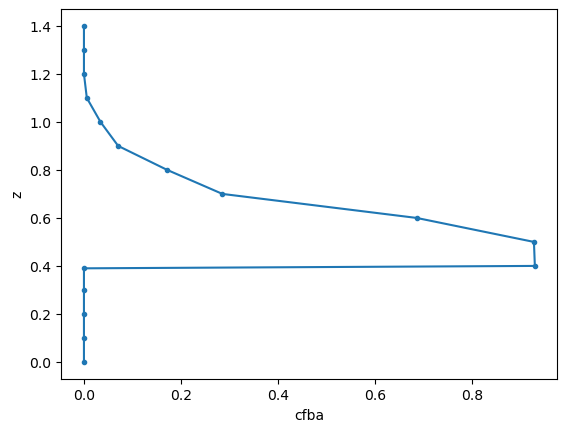

In [9]:
rte_grid['cfba'] = rte_grid.cloud_volume_mask.sum(('x','y')) / (rte_grid.sizes['x'] * rte_grid.sizes['y'])
rte_grid.cfba.plot(y='z', marker='.')

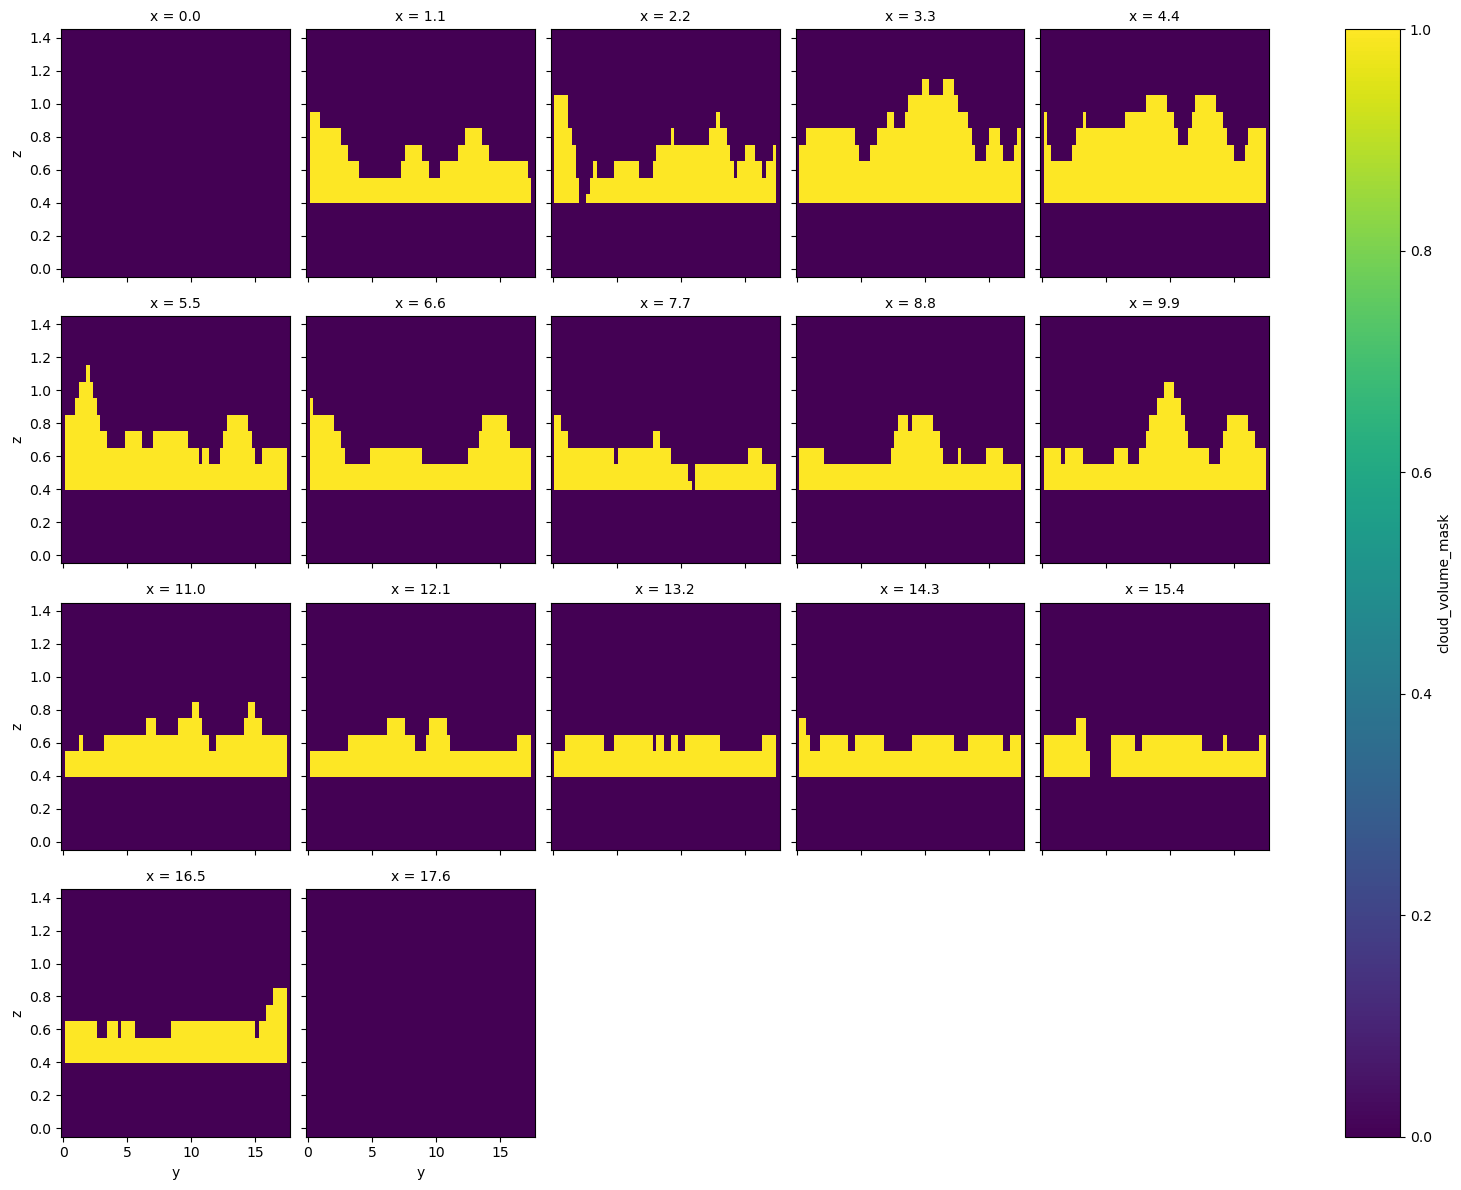

In [10]:
rte_grid.cloud_volume_mask.isel(x=slice(0,None,4)).plot(x='y', y='z', col='x', col_wrap=5)

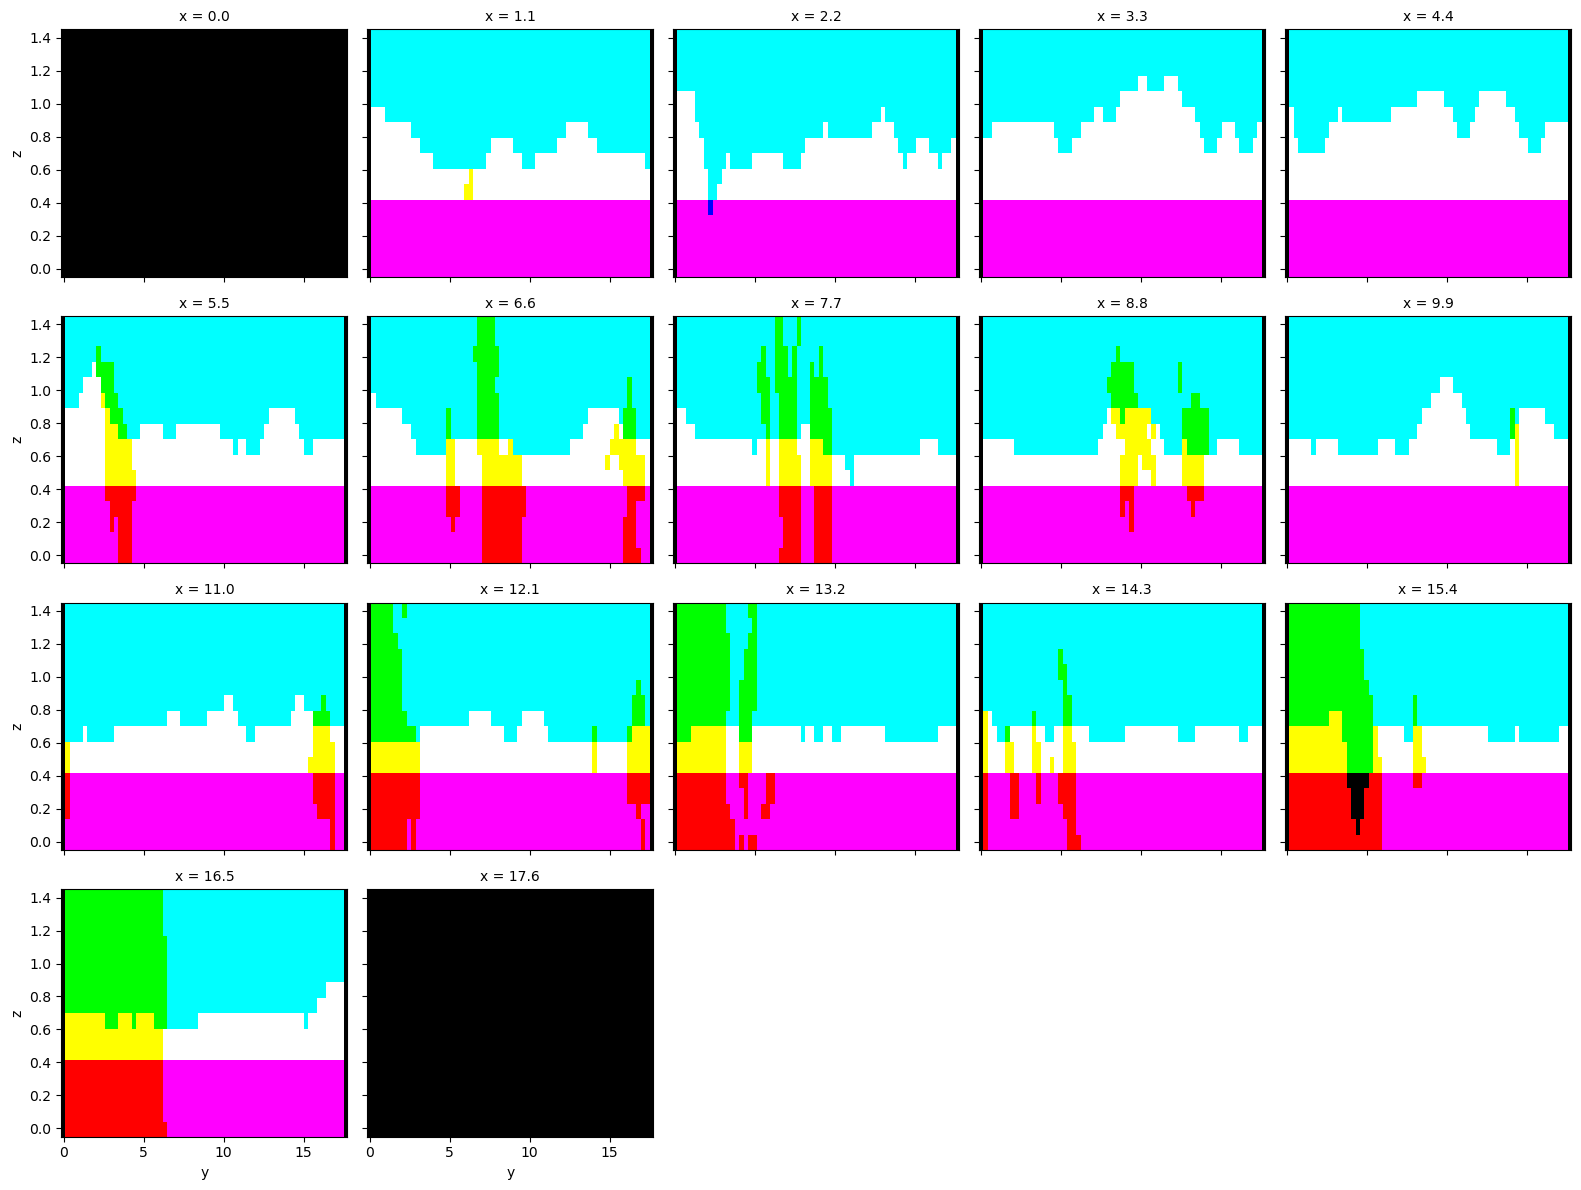

In [11]:
rte_grid.rbg_mask.isel(x=slice(0,None,4)).plot.imshow(x='y', y='z', col='x', col_wrap=5)